# Khám phá và phân tích dữ liệu văn bản

## 1. Tải dữ liệu (Tiny Shakespeare)
**Tiny Shakespeare** là bộ dữ liệu văn bản tiếng Anh được xây dựng từ các đoạn trích trong những vở kịch của William Shakespeare. Bộ dữ liệu này được Andrej Karpathy phổ biến trong dự án char-rnn, thường dùng để huấn luyện và thử nghiệm các mô hình ngôn ngữ như RNN, LSTM và Transformer (GPT)

In [3]:

import urllib.request
from pathlib import Path

URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

path = Path("../data/raw/input.txt")
path.parent.mkdir(parents=True, exist_ok=True)

try:
    request = urllib.request.Request(
        URL,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request, timeout=30) as response:
        content = response.read()

    path.write_bytes(content)

    text = content.decode("utf-8")

    print("Tải thành công!")
except Exception as e:
    print(f"Lỗi: {type(e).__name__}: {e}")


Tải thành công!


## Load dữ liệu

In [8]:

from pathlib import Path

path = Path("../data/raw/input.txt")
text = path.read_text(encoding="utf-8")

print("Tổng ký tự:", len(text))
print("Tổng bytes:", path.stat().st_size)
print("Dung lượng (MiB):", round(path.stat().st_size / 1024**2, 2))

print("\n500 ký tự đầu tiên:")
print(text[:500])


Tổng ký tự: 1115394
Tổng bytes: 1115394
Dung lượng (MiB): 1.06

500 ký tự đầu tiên:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## 2. Phân tích phân phối các ký tự

In [19]:

from collections import Counter

char_counts = Counter(text)

print("Vocabulary size:", len(char_counts))
print("Các ký tự:", repr("".join(sorted(char_counts))))

n = 20

print(f"\n{n} ký tự phổ biến nhất:")
for char, count in char_counts.most_common(n):
    print(f"{repr(char):8s}: {count:,}")


Vocabulary size: 65
Các ký tự: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"

20 ký tự phổ biến nhất:
' '     : 169,892
'e'     : 94,611
't'     : 67,009
'o'     : 65,798
'a'     : 55,507
'h'     : 51,310
's'     : 49,696
'r'     : 48,889
'n'     : 48,529
'i'     : 45,537
'\n'    : 40,000
'l'     : 33,339
'd'     : 31,358
'u'     : 26,584
'm'     : 22,243
'y'     : 20,448
','     : 19,846
'w'     : 17,585
'f'     : 15,770
'c'     : 15,623


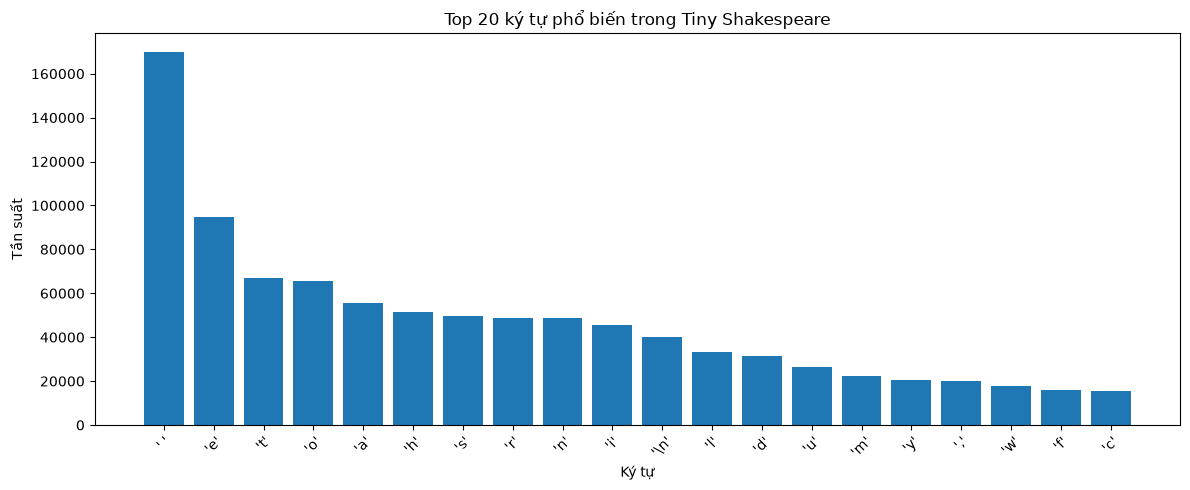

In [20]:

import matplotlib.pyplot as plt

top_chars = char_counts.most_common(n)
Path("../figure").mkdir(parents=True, exist_ok=True)

labels = [repr(char) for char, _ in top_chars]
values = [count for _, count in top_chars]

plt.figure(figsize=(12, 5))
plt.bar(labels, values)
plt.xlabel("Ký tự")
plt.ylabel("Tần suất")
plt.title(f"Top {n} ký tự phổ biến trong Tiny Shakespeare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../figure/char_distr.png", dpi=300, bbox_inches="tight")
plt.show()


## 3. Phân tích cấu trúc văn bản

In [21]:
import re
from collections import Counter

lines = text.splitlines()
words = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text)

print("Tổng dòng:", len(lines))
print("Dòng trống:", sum(not line.strip() for line in lines))
print("Tổng từ (ước lượng):", len(words))
print("Số từ khác nhau:", len(set(w.lower() for w in words)))

word_counts = Counter(w.lower() for w in words)

print("\n15 từ phổ biến:")
print(word_counts.most_common(15))

line_lengths = [len(line) for line in lines]

print("\nĐộ dài dòng trung bình:",
      sum(line_lengths) / len(line_lengths))
print("Độ dài dòng lớn nhất:", max(line_lengths))


Tổng dòng: 40000
Dòng trống: 7223
Tổng từ (ước lượng): 203839
Số từ khác nhau: 12373

15 từ phổ biến:
[('the', 6287), ('and', 5690), ('to', 4902), ('i', 4664), ('of', 3759), ('you', 3149), ('my', 3120), ('a', 3018), ('that', 2574), ('in', 2375), ('is', 2080), ('not', 2015), ('for', 1907), ('with', 1809), ('me', 1769)]

Độ dài dòng trung bình: 26.88485
Độ dài dòng lớn nhất: 63


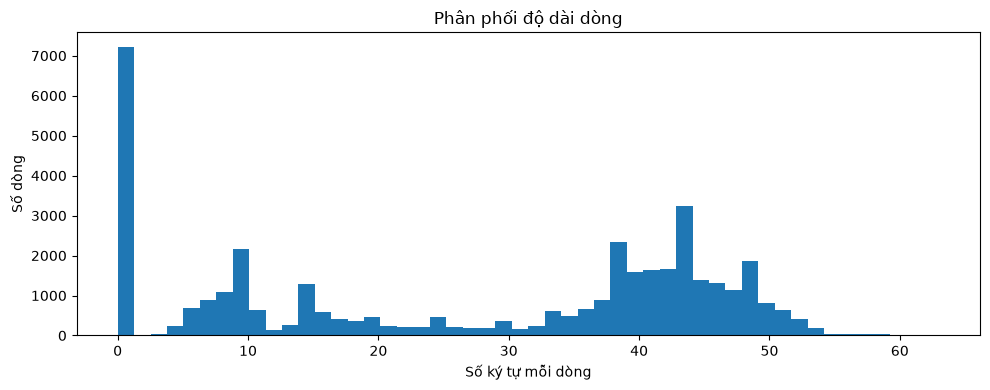

In [22]:

plt.figure(figsize=(10, 4))
plt.hist(line_lengths, bins=50)
plt.xlabel("Số ký tự mỗi dòng")
plt.ylabel("Số dòng")
plt.title("Phân phối độ dài dòng")
plt.tight_layout()
plt.savefig("../figure/line_distr.png", dpi=300, bbox_inches="tight")
plt.show()
